# Thematic Market Sectors: AI, Water, Robotics, Quantum Computing

Exploratory research on four thematic market sectors with public data only: market prices and company financials from Yahoo Finance, and sector statistics from Our World in Data, Epoch AI, and the World Bank, together with recent facts from primary sources. Market data ends at the close of 8 October 2026; the notebook was run on 9 October 2026.

This notebook is for information and research only. It is not investment advice. Past performance does not predict future results.

**How this notebook works.** Each sector has its own section: the market performance of thematic ETFs and leading listed companies, compared with the S&P 500 (SPY); sector statistics; company revenue; and a table of recent facts with links to their sources. The last section compares the four sectors.

**Measures.** Prices are adjusted for dividends and splits, so returns are total returns. Returns over 3 and 5 years are per year (compound annual growth). Volatility is the annualized standard deviation of daily log returns over the last year. Maximum drawdown is the largest fall from a previous high within the last 3 years. Beta is measured against the S&P 500 over the last year. Market values and revenue are the latest that Yahoo Finance reports when the notebook runs. Five-year returns are shown for ETFs only, because some companies listed through SPAC mergers in 2022 and their earlier prices are not comparable.

**Reproduce.** `pip install yfinance pandas numpy matplotlib seaborn plotly`, then run all cells. All data downloads when the notebook runs; change `AS_OF` to move the analysis date.

In [1]:
# Setup: libraries, the analysis date, and helpers for the public data sources.
# Needs: pip install yfinance pandas numpy matplotlib seaborn plotly
import io
import json
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import yfinance as yf

AS_OF = "2026-10-08"  # the last market close in this analysis
START = "2021-10-01"  # five years of history
pio.renderers.default = "plotly_mimetype+notebook_connected"
pio.templates.default = "plotly_white"
sns.set_theme(style="whitegrid")
UA = {"User-Agent": "Mozilla/5.0 (thematic sector research notebook)"}
SECTOR_COLORS = {
    "AI": "#4C78A8",
    "Water": "#54A24B",
    "Robotics": "#F58518",
    "Quantum Computing": "#B279A2",
    "Benchmark": "#7F7F7F",
}


def fetch(url: str) -> bytes:
    with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60) as r:
        return r.read()


def owid(slug: str) -> pd.DataFrame:
    """A chart dataset from Our World in Data (CSV, CC BY 4.0)."""
    url = (
        f"https://ourworldindata.org/grapher/{slug}.csv?v=1&csvType=full&useColumnShortNames=false"
    )
    return pd.read_csv(io.BytesIO(fetch(url)))


def world_bank(indicator: str, countries: str = "WLD;LIC;LMC;UMC;HIC") -> pd.DataFrame:
    """An indicator from the World Bank API (CC BY 4.0)."""
    url = (
        f"https://api.worldbank.org/v2/country/{countries}/indicator/{indicator}"
        "?format=json&per_page=2000"
    )
    rows = json.loads(fetch(url))[1]
    df = pd.DataFrame(
        [
            {"Group": r["country"]["value"], "Year": int(r["date"]), "Value": r["value"]}
            for r in rows
        ]
    )
    return df.dropna()

In [2]:
# Market data: thematic ETFs, benchmarks, and leading listed companies (Yahoo Finance).
SECTORS = {
    "AI": {
        "etfs": ["AIQ", "IGPT"],
        "companies": ["NVDA", "MSFT", "GOOGL", "AMZN", "META", "AVGO", "AMD", "TSM"],
    },
    "Water": {
        "etfs": ["PHO", "CGW", "FIW"],
        "companies": ["XYL", "AWK", "ECL", "VLTO", "PNR", "WTRG", "WTS", "VEOEY"],
    },
    "Robotics": {
        "etfs": ["BOTZ", "ROBO", "ARKQ"],
        "companies": ["ISRG", "ROK", "TER", "SYM", "CGNX", "ZBRA", "FANUY", "ABBNY"],
    },
    "Quantum Computing": {"etfs": ["QTUM"], "companies": ["IONQ", "RGTI", "QBTS", "QUBT", "IBM"]},
}
BENCHMARKS = ["SPY", "ACWI"]
SECTOR_OF = {t: s for s, g in SECTORS.items() for t in g["etfs"] + g["companies"]}
SECTOR_OF.update({t: "Benchmark" for t in BENCHMARKS})
TICKERS = list(SECTOR_OF)

prices = yf.download(TICKERS, start=START, end="2026-10-09", auto_adjust=True, progress=False)[
    "Close"
]
prices = prices.loc[:AS_OF]
returns = np.log(prices).diff()

info = {}
for t in TICKERS:  # names, currency, market value
    try:
        i = yf.Ticker(t).info
    except Exception:
        i = {}
    info[t] = {
        "name": i.get("longName") or i.get("shortName") or t,
        "currency": i.get("financialCurrency") or "USD",
        "market_cap": i.get("marketCap"),
    }
print(f"{prices.shape[1]} tickers, {prices.index[0].date()} to {prices.index[-1].date()}")

40 tickers, 2021-10-01 to 2026-10-08


In [3]:
# Helpers: performance and risk measures (prices adjusted for dividends and splits).
def annual_return(p: pd.Series, years: int) -> float:
    start = p.index[-1] - pd.DateOffset(years=years)
    window = p.loc[start:].dropna()
    if window.empty or window.index[0] - start > pd.Timedelta(days=7):
        return np.nan  # not enough history
    return ((window.iloc[-1] / window.iloc[0]) ** (1 / years) - 1) * 100


def max_drawdown(p: pd.Series) -> float:
    p = p.dropna()
    return (p / p.cummax() - 1).min() * 100


ETFS = {t for g in SECTORS.values() for t in g["etfs"]} | set(BENCHMARKS)


def performance(tickers: list[str]) -> pd.DataFrame:
    """Return, risk, and size of each ticker on AS_OF. Five-year returns for ETFs only: some
    companies listed through SPAC mergers in 2022, so their earlier prices are not comparable."""
    rows = []
    last_year = returns.loc[prices.index[-1] - pd.DateOffset(years=1) :]
    for t in tickers:
        p = prices[t].dropna()
        r = last_year[t].dropna()
        beta = r.cov(last_year["SPY"]) / last_year["SPY"].var()
        cap = info[t]["market_cap"]
        row = {
            "Ticker": t,
            "Name": info[t]["name"],
            "YTD (%)": (p.iloc[-1] / p.loc[: f"{p.index[-1].year - 1}-12-31"].iloc[-1] - 1) * 100,
            "1 year (%)": annual_return(p, 1),
            "3 years, per year (%)": annual_return(p, 3),
        }
        row["5 years, per year (%)"] = annual_return(p, 5) if t in ETFS else np.nan
        row.update(
            {
                "Volatility, 1 year (%)": r.std() * np.sqrt(252) * 100,
                "Max drawdown, 3 years (%)": max_drawdown(
                    p.loc[p.index[-1] - pd.DateOffset(years=3) :]
                ),
                "Beta to S&P 500": beta,
                "Market value (US$ bn)": cap / 1e9 if cap else np.nan,
            }
        )
        rows.append(row)
    return pd.DataFrame(rows).set_index("Ticker").round(2)


def indexed(tickers: list[str], since: str) -> pd.DataFrame:
    """Prices indexed to 100 on the first day."""
    p = prices[tickers].loc[since:].dropna()
    return p / p.iloc[0] * 100


def revenue_table(tickers: list[str]) -> pd.DataFrame:
    """Annual total revenue of the last four fiscal years (reporting currency, billions)."""
    rows = {}
    for t in tickers:
        inc = yf.Ticker(t).income_stmt
        if "Total Revenue" not in inc.index:
            continue
        s = inc.loc["Total Revenue"].dropna().sort_index() / 1e9
        rows[t] = pd.Series(s.values, index=[f"FY{d.year}" for d in s.index])
    return pd.DataFrame(rows).T


def line_chart(df: pd.DataFrame, title: str, y: str, log: bool = False):
    fig = px.line(df, title=title, labels={"value": y, "Date": "", "variable": ""}, log_y=log)
    fig.update_layout(legend_title_text="", hovermode="x unified")
    return fig

## Artificial Intelligence

AI is the largest and fastest-growing theme in this notebook, measured by investment, company revenue, and market value. Private investment in AI more than doubled in 2025, and the United States received about 83% of it. Over the last year the AI ETFs beat the S&P 500 (AIQ +27.4%, IGPT +73.4%, SPY +16.2%), with about twice the volatility. Among the leading companies, the results diverged: AMD rose 163% while Microsoft and Meta were nearly flat.

AI ETFs and the S&P 500 over five years. Global X Artificial Intelligence & Technology (AIQ) and Invesco AI and Next Gen Software (IGPT), indexed to 100 on 1 October 2021. Both fell more than the market in 2022 and have led it since 2023.

In [4]:
etfs = SECTORS["AI"]["etfs"] + ["SPY"]
fig = line_chart(
    indexed(etfs, START), "AI ETFs and the S&P 500, last 5 years", "Indexed to 100 (Oct 2021)"
)
fig.show()

Performance and risk of AI ETFs and leading AI companies. Over three years the ETFs returned 34% (AIQ) and 44% (IGPT) per year, against 23% for the S&P 500; NVIDIA returned 72% per year, Taiwan Semiconductor 75%, and AMD 80%. Betas near 2 mean that the ETFs moved about twice as much as the market.

In [5]:
ai_perf = performance(SECTORS["AI"]["etfs"] + ["SPY"] + SECTORS["AI"]["companies"])
ai_perf

,Name,YTD (%),1 year (%),"3 years, per year (%)","5 years, per year (%)","Volatility, 1 year (%)","Max drawdown, 3 years (%)",Beta to S&P 500,Market value (US$ bn)
Ticker,,,,,,,,,
AIQ,Global X Artificial Intelligence & Technology ETF,28.98,27.37,33.99,16.75,29.47,-26.35,1.93,NaN
IGPT,Invesco AI and Next Gen Software ETF,68.15,73.43,44.34,17.59,38.49,-29.30,2.31,NaN
SPY,State Street SPDR S&P 500 ETF Trust,14.38,16.22,22.90,13.58,13.01,-18.76,1.00,NaN
NVDA,NVIDIA Corporation,23.87,22.17,72.20,NaN,37.71,-36.88,1.89,5565.40
MSFT,Microsoft Corporation,8.75,0.39,17.49,NaN,32.32,-34.50,0.96,3880.66
GOOGL,Alphabet Inc.,11.49,42.75,36.44,NaN,31.42,-29.81,1.34,4259.56
AMZN,"Amazon.com, Inc.",10.07,12.81,25.59,NaN,33.93,-30.88,1.44,2740.37
META,"Meta Platforms, Inc.",9.49,0.77,31.73,NaN,41.78,-34.15,1.45,1836.47
AVGO,Broadcom Inc.,4.63,5.01,63.20,NaN,47.15,-41.15,2.18,1719.18


Annual revenue of leading AI companies, last four fiscal years. NVIDIA's revenue grew from US$27.0 billion (fiscal year to January 2023) to US$215.9 billion (fiscal year to January 2026), eight times as much. Fiscal years end in different months; Taiwan Semiconductor reports in New Taiwan dollars and is not shown.

In [6]:
ai_revenue = revenue_table([t for t in SECTORS["AI"]["companies"] if info[t]["currency"] == "USD"])
fig = px.bar(
    ai_revenue.reset_index().melt(id_vars="index", var_name="Fiscal year", value_name="Revenue"),
    x="index",
    y="Revenue",
    color="Fiscal year",
    barmode="group",
    title="Annual revenue of leading AI companies",
    labels={"index": "", "Revenue": "US$ billion"},
)
fig.show()

Private investment in AI by region, 2013 to 2025. Data: Quid via the Stanford AI Index 2026, from Our World in Data, in constant 2021 US dollars (so the totals are lower than the nominal figures in the facts table). World private investment rose from US$130.9 billion in 2024 to US$290.1 billion in 2025; the United States received US$240.6 billion, about 83%.

In [7]:
invest = owid("private-investment-in-artificial-intelligence")
invest["US$ billion (2021 prices)"] = invest["Private investment in AI by region"] / 1e9
fig = px.line(
    invest,
    x="Year",
    y="US$ billion (2021 prices)",
    color="Entity",
    markers=True,
    title="Private investment in AI by region, 2013-2025 (US$ billion, constant 2021 prices)",
)
fig.show()

Training compute of notable AI models since 2010. Data: Epoch AI, notable AI models (updated October 2026). Each point is a model; the log scale shows exponential growth. Epoch AI reports that training compute for frontier language models has grown about 5 times per year since 2020.

In [8]:
models = pd.read_csv(io.BytesIO(fetch("https://epoch.ai/data/notable_ai_models.csv")))
models["Published"] = pd.to_datetime(models["Publication date"])
models["Domain"] = models["Domain"].fillna("Other").str.split(",").str[0]
models = models.dropna(subset=["Training compute (FLOP)"]).query("Published >= '2010-01-01'")
fig = px.scatter(
    models,
    x="Published",
    y="Training compute (FLOP)",
    color="Domain",
    log_y=True,
    hover_name="Model",
    hover_data=["Organization"],
    title="Training compute of notable AI models since 2010 (FLOP, log scale)",
)
fig.show()

Large-scale AI systems by country, cumulative to 2025. Data: Epoch AI via Our World in Data. Of 497 large-scale systems, 221 come from the United States and 194 from China; France (20) and South Korea (18) follow.

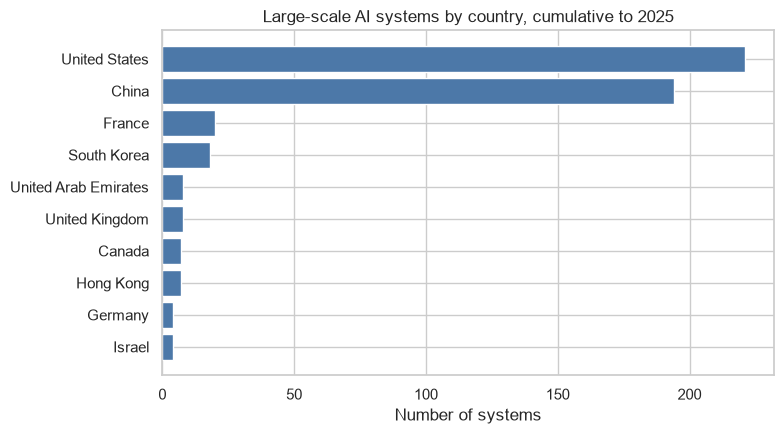

In [9]:
systems = owid("cumulative-number-of-large-scale-ai-systems-by-country")
latest = systems[systems["Year"] == systems["Year"].max()]
latest = latest[~latest["Entity"].isin(["All large-scale AI systems"])]
top = latest.nlargest(10, "Cumulative number of large-scale AI systems by country").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    top["Entity"], top["Cumulative number of large-scale AI systems by country"], color="#4C78A8"
)
ax.set_title(f"Large-scale AI systems by country, cumulative to {int(latest['Year'].max())}")
ax.set_xlabel("Number of systems")
plt.tight_layout()
plt.show()

Key facts about AI from recent public sources. Each row links to the page where the number appears.

In [10]:
ai_facts = pd.DataFrame(
    [
        (
            "Global corporate AI investment reached US$581.7 billion in 2025, up 130% from 2024; private investment was US$344.7 billion.",
            "Stanford HAI, AI Index 2026 (12 takeaways)",
            "2026-04-13",
            "https://hai.stanford.edu/news/inside-the-ai-index-12-takeaways-from-the-2026-report",
        ),
        (
            "US private AI investment was US$285.9 billion in 2025, 23 times China's US$12.4 billion.",
            "Stanford HAI, AI Index 2026 (12 takeaways)",
            "2026-04-13",
            "https://hai.stanford.edu/news/inside-the-ai-index-12-takeaways-from-the-2026-report",
        ),
        (
            "88% of surveyed organizations used AI in 2025, up from 55% in 2023.",
            "Stanford HAI, AI Index 2026, Economy chapter",
            "2026-04-13",
            "https://hai.stanford.edu/ai-index/2026-ai-index-report/economy",
        ),
        (
            "Between December 2025 and May 2026, 17% to 20% of US businesses reported using AI; 37% of firms with 250 or more employees.",
            "US Census Bureau, Business Trends and Outlook Survey",
            "2026-05-26",
            "https://census.gov/library/stories/2026/05/ai-use-businesses.html",
        ),
        (
            "Capital expenditure of the largest technology companies exceeded US$400 billion in 2025; the IEA expects it to rise about 75% in 2026.",
            "IEA, Key Questions on Energy and AI",
            "2026-04-16",
            "https://www.iea.org/reports/key-questions-on-energy-and-ai/executive-summary",
        ),
        (
            "Alphabet's purchases of property and equipment were US$44.9 billion in Q2 2026, against US$22.4 billion in Q2 2025.",
            "Alphabet, Q2 2026 earnings release (SEC Form 8-K)",
            "2026-07-22",
            "https://www.sec.gov/Archives/edgar/data/0001652044/000165204426000066/googexhibit991q22026.htm",
        ),
        (
            "Meta's capital expenditure, including finance leases, was US$31.08 billion in Q2 2026; its 2026 guidance is US$130 to 145 billion.",
            "Meta, Second Quarter 2026 Results",
            "2026-07-29",
            "https://investor.atmeta.com/investor-news/press-release-details/2026/Meta-Reports-Second-Quarter-2026-Results/default.aspx",
        ),
        (
            "NVIDIA's Data Center revenue was US$89.0 billion in Q2 of fiscal 2027 (to 26 July 2026), up 117% year on year; total revenue was US$96.2 billion.",
            "NVIDIA, Q2 fiscal 2027 results",
            "2026-08-26",
            "https://nvidianews.nvidia.com/news/nvidia-announces-financial-results-for-second-quarter-fiscal-2027",
        ),
        (
            "Data-centre electricity use is projected to roughly double from 485 TWh in 2025 to 950 TWh in 2030, about 3% of global electricity demand.",
            "IEA, Key Questions on Energy and AI",
            "2026-04-16",
            "https://www.iea.org/reports/key-questions-on-energy-and-ai/executive-summary",
        ),
        (
            "Training compute for frontier language models has grown about 5 times per year since 2020.",
            "Epoch AI, Trends",
            "2026-02-05",
            "https://epoch.ai/trends",
        ),
        (
            "The EU AI Act became applicable on 2 August 2026; obligations for high-risk AI systems listed in Annex III start on 2 December 2027.",
            "European Commission, AI Act",
            "2026-08-03",
            "https://digital-strategy.ec.europa.eu/en/policies/regulatory-framework-ai",
        ),
    ],
    columns=["Fact", "Source", "Published", "Link"],
)
ai_facts

,Fact,Source,Published,Link
0,Global corporate AI investment reached US$581....,"Stanford HAI, AI Index 2026 (12 takeaways)",2026-04-13,https://hai.stanford.edu/news/inside-the-ai-in...
1,US private AI investment was US$285.9 billion ...,"Stanford HAI, AI Index 2026 (12 takeaways)",2026-04-13,https://hai.stanford.edu/news/inside-the-ai-in...
2,"88% of surveyed organizations used AI in 2025,...","Stanford HAI, AI Index 2026, Economy chapter",2026-04-13,https://hai.stanford.edu/ai-index/2026-ai-inde...
3,"Between December 2025 and May 2026, 17% to 20%...","US Census Bureau, Business Trends and Outlook ...",2026-05-26,https://census.gov/library/stories/2026/05/ai-...
4,Capital expenditure of the largest technology ...,"IEA, Key Questions on Energy and AI",2026-04-16,https://www.iea.org/reports/key-questions-on-e...
5,Alphabet's purchases of property and equipment...,"Alphabet, Q2 2026 earnings release (SEC Form 8-K)",2026-07-22,https://www.sec.gov/Archives/edgar/data/000165...
6,"Meta's capital expenditure, including finance ...","Meta, Second Quarter 2026 Results",2026-07-29,https://investor.atmeta.com/investor-news/pres...
7,NVIDIA's Data Center revenue was US$89.0 billi...,"NVIDIA, Q2 fiscal 2027 results",2026-08-26,https://nvidianews.nvidia.com/news/nvidia-anno...
8,Data-centre electricity use is projected to ro...,"IEA, Key Questions on Energy and AI",2026-04-16,https://www.iea.org/reports/key-questions-on-e...
9,Training compute for frontier language models ...,"Epoch AI, Trends",2026-02-05,https://epoch.ai/trends


## Water

Water is the defensive theme in this notebook: its ETFs moved less than the market (betas of 0.6 to 0.7) and returned less. Over the last year the water ETFs returned between -7.8% and +1.0%, while the S&P 500 returned 16.2%. The need is large: in 2024, 2.1 billion people (26% of the world's population) still did not use safely managed drinking water, and 16 countries withdraw more fresh water than they renew. American Water Works and Essential Utilities, both in the table below, have announced a merger.

Water ETFs and the S&P 500 over five years. Invesco Water Resources (PHO), Invesco S&P Global Water Index (CGW), and First Trust Water (FIW), indexed to 100 on 1 October 2021. Over five years the ETFs returned 4% to 5% per year, against 14% for the S&P 500.

In [11]:
etfs = SECTORS["Water"]["etfs"] + ["SPY"]
fig = line_chart(
    indexed(etfs, START), "Water ETFs and the S&P 500, last 5 years", "Indexed to 100 (Oct 2021)"
)
fig.show()

Performance and risk of water ETFs and leading water companies. Results over the last year varied widely: Watts Water rose 25% and Veolia 10%, while Xylem fell 30% and Pentair 53%. Two utilities, American Water Works and Essential Utilities, had negative betas: they tended to move against the market over the last year.

In [12]:
water_perf = performance(SECTORS["Water"]["etfs"] + ["SPY"] + SECTORS["Water"]["companies"])
water_perf

,Name,YTD (%),1 year (%),"3 years, per year (%)","5 years, per year (%)","Volatility, 1 year (%)","Max drawdown, 3 years (%)",Beta to S&P 500,Market value (US$ bn)
Ticker,,,,,,,,,
PHO,Invesco Water Resources ETF,-2.79,-6.90,9.12,4.78,15.77,-19.19,0.63,NaN
CGW,Invesco S&P Global Water Index ETF,1.02,1.01,13.27,4.27,13.81,-14.19,0.59,NaN
FIW,First Trust Water ETF,-3.24,-7.77,8.90,4.58,16.11,-18.32,0.71,NaN
SPY,State Street SPDR S&P 500 ETF Trust,14.38,16.22,22.90,13.58,13.01,-18.76,1.00,NaN
XYL,Xylem Inc.,-24.27,-30.21,5.14,NaN,25.46,-33.12,0.78,23.81
AWK,"American Water Works Company, Inc.",0.26,-6.63,4.51,NaN,22.25,-18.81,-0.44,25.47
ECL,Ecolab Inc.,8.17,1.21,20.11,NaN,22.04,-20.09,0.48,78.97
VLTO,Veralto Corporation,-2.89,-6.71,9.45,NaN,23.06,-27.09,0.28,23.52
PNR,Pentair plc,-49.28,-52.65,-5.26,NaN,33.47,-53.08,0.93,8.45


Annual revenue of leading water companies, last four fiscal years. Revenue grew steadily but slowly: Xylem from US$5.5 billion (2022) to US$9.0 billion (2025), American Water Works from US$3.8 billion to US$5.1 billion. Veolia reports in euros and is not shown.

In [13]:
water_revenue = revenue_table(
    [t for t in SECTORS["Water"]["companies"] if info[t]["currency"] == "USD"]
)
fig = px.bar(
    water_revenue.reset_index().melt(id_vars="index", var_name="Fiscal year", value_name="Revenue"),
    x="index",
    y="Revenue",
    color="Fiscal year",
    barmode="group",
    title="Annual revenue of leading water companies",
    labels={"index": "", "Revenue": "US$ billion"},
)
fig.show()

People using safely managed drinking water services, by income group, 2000 to 2024. Data: WHO/UNICEF Joint Monitoring Programme via the World Bank (indicator SH.H2O.SMDW.ZS). The world share rose from 61% (2000) to 74% (2024). In low-income countries it was 33% in 2024, against 96% in high-income countries. The upper-middle-income series has a one-year dip in 2023 in the source data.

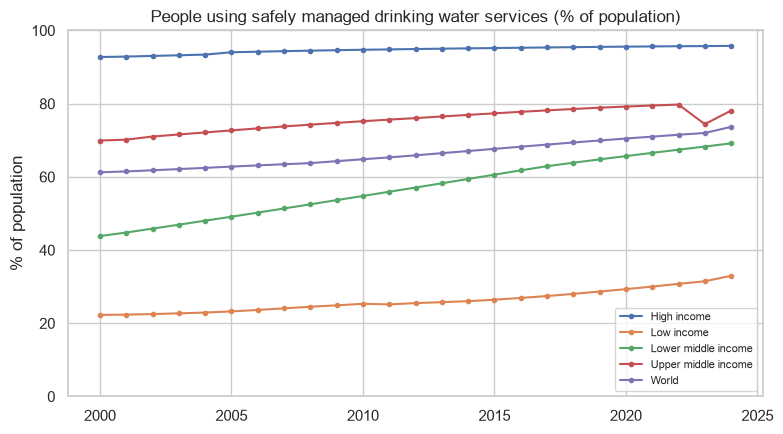

In [14]:
drinking = world_bank("SH.H2O.SMDW.ZS")
fig, ax = plt.subplots(figsize=(8, 4.5))
for group, d in drinking.sort_values("Year").groupby("Group"):
    ax.plot(d["Year"], d["Value"], marker="o", markersize=3, label=group)
ax.set_title("People using safely managed drinking water services (% of population)")
ax.set_ylabel("% of population")
ax.set_ylim(0, 100)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Water stress: freshwater withdrawals as a share of available freshwater resources, the 15 most stressed countries. Data: FAO AQUASTAT via Our World in Data (SDG indicator 6.4.2), latest year 2023. The world level is 17.6%; above 100%, a country withdraws more than its renewable resources (for example through desalination or fossil groundwater). Kuwait is at 3,851%, the United Arab Emirates at 1,437%.

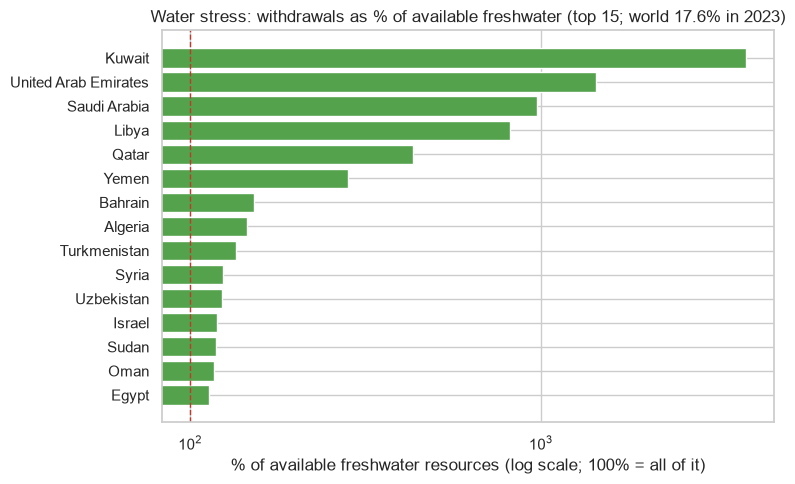

In [15]:
stress = owid("freshwater-withdrawals-as-a-share-of-internal-resources")
col = stress.columns[-1]
countries = stress[stress["Code"].notna() & ~stress["Code"].astype(str).str.startswith("OWID")]
latest = countries.sort_values("Year").groupby("Entity").tail(1)
top = latest.nlargest(15, col).iloc[::-1]
world = stress[stress["Entity"] == "World"].sort_values("Year").iloc[-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Entity"], top[col], color="#54A24B")
ax.axvline(100, color="#C0392B", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_title(
    f"Water stress: withdrawals as % of available freshwater (top 15; world {world[col]:.1f}% in {int(world['Year'])})"
)
ax.set_xlabel("% of available freshwater resources (log scale; 100% = all of it)")
plt.tight_layout()
plt.show()

Key facts about water from recent public sources. Each row links to the page where the number appears.

In [16]:
water_facts = pd.DataFrame(
    [
        (
            "In 2024, 2.1 billion people lacked safely managed drinking water, 3.4 billion lacked safely managed sanitation, and 1.7 billion lacked basic hygiene at home.",
            "WHO/UNICEF Joint Monitoring Programme",
            "2025-08-26",
            "https://www.who.int/news/item/26-08-2025-1-in-4-people-globally-still-lack-access-to-safe-drinking-water---who--unicef",
        ),
        (
            "Women and girls spend 250 million hours a day collecting water; women collect it in over 70% of rural households without a water service.",
            "UNESCO for UN-Water, World Water Development Report 2026",
            "2026-03-19",
            "https://www.unesco.org/en/articles/global-water-crisis-aggravated-gender-inequalities-according-new-un-report",
        ),
        (
            "Only 34% to 38% of river basins had normal flows in recent years (1991-2020 average: 46%); glaciers lost 408 gigatonnes of ice in 2025.",
            "WMO, State of Global Water Resources 2025",
            "2026-09-17",
            "https://wmo.int/news/media-centre/wmo-recent-water-trends-have-serious-future-implications",
        ),
        (
            "The World Bank Group launched 'Water Forward' to improve water security for 1 billion people by 2030, 400 million of them through its own work.",
            "World Bank",
            "2026-04-15",
            "https://www.worldbank.org/en/news/press-release/2026/04/15/world-bank-group-launches-initiative-to-improve-water-security-for-1-billion-people",
        ),
        (
            "The US EPA proposed an option for drinking water systems to have two more years, to 2031, to meet the 4.0 ppt limits for PFOA and PFOS (a proposal, not yet final).",
            "US EPA",
            "2026-10-08",
            "https://www.epa.gov/sdwa/proposed-pfoa-and-pfos-compliance-extension-rule",
        ),
        (
            "The water footprint of data-centre electricity use is projected at 9.3 trillion litres in 2030 (cooling water and the water used to generate the power).",
            "United Nations University (UNU-INWEH)",
            "2026-06-03",
            "https://unu.edu/inweh/news/environmental-cost-of-AIs-Enrgy-use-carbon-water-and-land-footprints",
        ),
        (
            "Quaternary wastewater treatment (removal of micropollutants) under the revised EU Urban Wastewater Treatment Directive is estimated at EUR 1.48 to 1.8 billion a year by 2045.",
            "European Commission, Joint Research Centre (JRC144745)",
            "2025-12-10",
            "https://publications.jrc.ec.europa.eu/repository/handle/JRC144745",
        ),
        (
            "American Water plans capital investment of US$19 to 20 billion for 2026-2030 and US$46 to 48 billion for 2026-2035; it announced a merger with Essential Utilities, expected to close in Q1 2027.",
            "American Water Works, Q3 2025 results",
            "2025-10-29",
            "https://www.amwater.com/press-room/press-releases/corporate/american-water-reports-strong-third-quarter-2025-results-affirms-long-term-targets-and-2025-eps-guidance-initiates-2026-eps-guidance-reflecting-growth-of-8-announced-merger-with-essential-utilities-expected-closing-q1-2027",
        ),
        (
            "Xylem's 2025 revenue was US$9.0 billion, up 6% (5% organically); its 2026 guidance is US$9.1 to 9.2 billion.",
            "Xylem, Q4 2025 results (SEC Form 8-K)",
            "2026-02-10",
            "https://www.sec.gov/Archives/edgar/data/1524472/000152447226000008/xyl02102026ex991.htm",
        ),
        (
            "Veolia's water businesses had revenue of EUR 17.7 billion in 2025, of which Water Technologies EUR 4.95 billion (+3.6% like for like).",
            "Veolia, 2025 annual results",
            "2026-02-26",
            "https://www.veolia.com/sites/g/files/dvc4206/files/document/2026/02/Finance_PR_Veolia_2025_results.pdf",
        ),
    ],
    columns=["Fact", "Source", "Published", "Link"],
)
water_facts

,Fact,Source,Published,Link
0,"In 2024, 2.1 billion people lacked safely mana...",WHO/UNICEF Joint Monitoring Programme,2025-08-26,https://www.who.int/news/item/26-08-2025-1-in-...
1,Women and girls spend 250 million hours a day ...,"UNESCO for UN-Water, World Water Development R...",2026-03-19,https://www.unesco.org/en/articles/global-wate...
2,Only 34% to 38% of river basins had normal flo...,"WMO, State of Global Water Resources 2025",2026-09-17,https://wmo.int/news/media-centre/wmo-recent-w...
3,The World Bank Group launched 'Water Forward' ...,World Bank,2026-04-15,https://www.worldbank.org/en/news/press-releas...
4,The US EPA proposed an option for drinking wat...,US EPA,2026-10-08,https://www.epa.gov/sdwa/proposed-pfoa-and-pfo...
5,The water footprint of data-centre electricity...,United Nations University (UNU-INWEH),2026-06-03,https://unu.edu/inweh/news/environmental-cost-...
6,Quaternary wastewater treatment (removal of mi...,"European Commission, Joint Research Centre (JR...",2025-12-10,https://publications.jrc.ec.europa.eu/reposito...
7,American Water plans capital investment of US$...,"American Water Works, Q3 2025 results",2025-10-29,https://www.amwater.com/press-room/press-relea...
8,"Xylem's 2025 revenue was US$9.0 billion, up 6%...","Xylem, Q4 2025 results (SEC Form 8-K)",2026-02-10,https://www.sec.gov/Archives/edgar/data/152447...
9,Veolia's water businesses had revenue of EUR 1...,"Veolia, 2025 annual results",2026-02-26,https://www.veolia.com/sites/g/files/dvc4206/f...


## Robotics

Robot installations reached a new record, and China installs more than half of the world's industrial robots. The International Federation of Robotics (IFR) reports that more than 600,000 industrial robots were installed in 2025 and that 5 million now operate worldwide; China installed 354,000 (59%). Market returns were mixed: over the last year ROBO returned +17.4% and BOTZ -6.0%, against +16.2% for the S&P 500, while Teradyne rose 176% and Symbotic fell 39%.

Robotics ETFs and the S&P 500 over five years. Global X Robotics & Artificial Intelligence (BOTZ), ROBO Global Robotics and Automation (ROBO), and ARK Autonomous Technology & Robotics (ARKQ), indexed to 100 on 1 October 2021. Over five years BOTZ returned -0.1% per year and ROBO 5.0%, against 13.6% for the S&P 500.

In [17]:
etfs = SECTORS["Robotics"]["etfs"] + ["SPY"]
fig = line_chart(
    indexed(etfs, START), "Robotics ETFs and the S&P 500, last 5 years", "Indexed to 100 (Oct 2021)"
)
fig.show()

Performance and risk of robotics ETFs and leading robotics and automation companies. Volatility is high: 27% to 35% for the ETFs and up to 79% (Symbotic) for single companies. Intuitive Surgical, the largest surgical robotics company, fell 7% over the last year, while ABB rose 30%.

In [18]:
robotics_perf = performance(
    SECTORS["Robotics"]["etfs"] + ["SPY"] + SECTORS["Robotics"]["companies"]
)
robotics_perf

,Name,YTD (%),1 year (%),"3 years, per year (%)","5 years, per year (%)","Volatility, 1 year (%)","Max drawdown, 3 years (%)",Beta to S&P 500,Market value (US$ bn)
Ticker,,,,,,,,,
BOTZ,Global X Robotics & Artificial Intelligence ETF,-3.82,-6.02,12.62,-0.08,26.70,-29.02,1.70,NaN
ROBO,Robo Global Robotics and Automation Index ETF,15.54,17.40,17.71,4.95,27.26,-27.92,1.77,NaN
ARKQ,ARK Autonomous Technology & Robotics ETF,6.81,-0.16,32.64,9.45,34.92,-30.76,2.18,NaN
SPY,State Street SPDR S&P 500 ETF Trust,14.38,16.22,22.90,13.58,13.01,-18.76,1.00,NaN
ISRG,"Intuitive Surgical, Inc.",-26.65,-7.29,12.15,NaN,37.01,-45.61,0.93,146.76
ROK,"Rockwell Automation, Inc.",12.66,26.38,16.23,NaN,31.01,-28.01,1.37,48.21
TER,"Teradyne, Inc.",106.24,176.27,59.65,NaN,77.29,-58.18,3.26,62.34
SYM,Symbotic Inc.,-29.31,-38.89,4.54,NaN,79.40,-69.93,2.88,25.46
CGNX,Cognex Corporation,70.01,31.13,14.61,NaN,57.05,-55.74,2.01,10.25


Industrial robots installed per year, 2011 to 2024. Data: IFR World Robotics via Our World in Data, which does not yet include 2025 (the IFR's September 2026 figures for 2025 are in the facts table). World installations were 542,000 units in 2024: China 295,000, Japan 45,000, the United States 34,000, South Korea 31,000, and Germany 27,000.

In [19]:
robots = owid("annual-industrial-robots-installed")
robots["Thousand units"] = robots["Annual industrial robots installed"] / 1000
fig = px.line(
    robots,
    x="Year",
    y="Thousand units",
    color="Entity",
    markers=True,
    title="Industrial robots installed per year, 2011-2024 (thousand units)",
)
fig.show()

Share of world industrial robot installations by country. Calculated from the same IFR data. China's share rose from 14% in 2012 to 54% in 2024 (59% in 2025, according to the IFR), while the shares of Japan, the United States, South Korea, and Germany each fell below 9%.

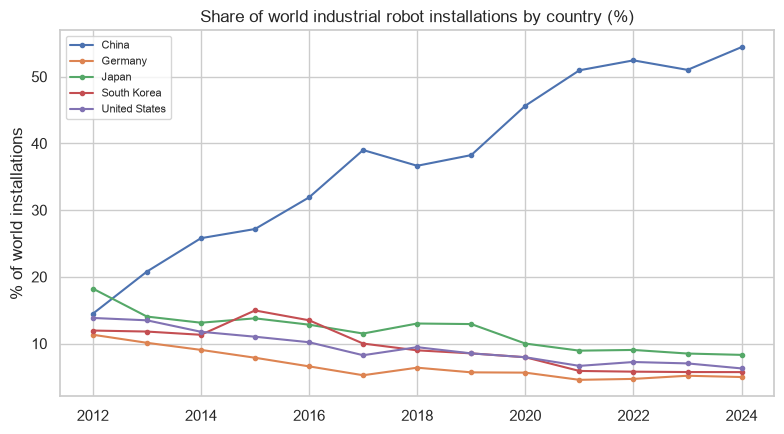

In [20]:
wide = robots.pivot(index="Year", columns="Entity", values="Annual industrial robots installed")
share = wide.drop(columns="World").div(wide["World"], axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
share.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Share of world industrial robot installations by country (%)")
ax.set_ylabel("% of world installations")
ax.set_xlabel("")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Annual revenue of leading robotics and automation companies, last four fiscal years. Intuitive Surgical grew from US$6.2 billion (2022) to US$10.1 billion (2025) and Symbotic from US$0.6 billion to US$2.2 billion; Rockwell Automation and Teradyne were flat. Fanuc reports in yen and is not shown.

In [21]:
robotics_revenue = revenue_table(
    [t for t in SECTORS["Robotics"]["companies"] if info[t]["currency"] == "USD"]
)
fig = px.bar(
    robotics_revenue.reset_index().melt(
        id_vars="index", var_name="Fiscal year", value_name="Revenue"
    ),
    x="index",
    y="Revenue",
    color="Fiscal year",
    barmode="group",
    title="Annual revenue of leading robotics and automation companies",
    labels={"index": "", "Revenue": "US$ billion"},
)
fig.show()

Key facts about robotics from recent public sources. Each row links to the page where the number appears.

In [22]:
robotics_facts = pd.DataFrame(
    [
        (
            "The number of industrial robots in operation rose 9% to a record 5 million in 2025; more than 600,000 were installed in 2025 (+11%).",
            "International Federation of Robotics (IFR), World Robotics 2026",
            "2026-09-24",
            "https://ifr.org/ifr-press-releases/news/five-million-robots-now-operate-in-factories-globally",
        ),
        (
            "China installed 354,000 industrial robots in 2025 (+20%), 59% of the world total; Chinese suppliers had 55% of their home market.",
            "IFR, World Robotics 2026",
            "2026-09-24",
            "https://ifr.org/ifr-press-releases/news/five-million-robots-now-operate-in-factories-globally",
        ),
        (
            "The United States installed almost 38,500 robots in 2025 (+12%) and passed Japan (36,219, -19%) as the second-largest market; South Korea installed 30,000 and Germany fewer than 25,000.",
            "IFR, World Robotics 2026",
            "2026-09-24",
            "https://ifr.org/ifr-press-releases/news/five-million-robots-now-operate-in-factories-globally",
        ),
        (
            "The IFR forecasts 655,000 robot installations in 2026 (+9%) and 806,000 in 2029.",
            "IFR, World Robotics 2026",
            "2026-09-24",
            "https://ifr.org/ifr-press-releases/news/five-million-robots-now-operate-in-factories-globally",
        ),
        (
            "Robot density in 2024 (robots per 10,000 manufacturing employees): South Korea 1,220, Singapore 818, Germany 449, Japan 446; world average 132.",
            "IFR, robot density",
            "2026-04-08",
            "https://ifr.org/ifr-press-releases/news/robot-density-surges-in-europe-asia-and-americas",
        ),
        (
            "Sales of professional service robots rose 24% to almost 250,000 units in 2025; transport and logistics robots were 117,500 of them (47%).",
            "IFR, World Robotics 2026 (service robots)",
            "2026-09-30",
            "https://ifr.org/ifr-press-releases/news/global-sales-of-professional-service-robots-surge-24-percent",
        ),
        (
            "About 7,000 full-size humanoid robots were sold worldwide in 2025; most uses are still specialized and often need remote operation.",
            "IFR, World Robotics 2026 (service robots)",
            "2026-09-30",
            "https://ifr.org/ifr-press-releases/news/global-sales-of-professional-service-robots-surge-24-percent",
        ),
        (
            "8,400 surgical robots were sold in 2025, up 57%.",
            "IFR, World Robotics 2026 (service robots)",
            "2026-09-30",
            "https://ifr.org/ifr-press-releases/news/global-sales-of-professional-service-robots-surge-24-percent",
        ),
        (
            "Intuitive Surgical: worldwide procedures grew about 16% in Q2 2026; it placed 468 da Vinci systems (395 a year earlier), and the da Vinci installed base reached 11,710 (+12%).",
            "Intuitive Surgical, Q2 2026 earnings release (SEC Form 8-K)",
            "2026-07-16",
            "https://www.sec.gov/Archives/edgar/data/0001035267/000103526726000047/q226ex-991earningsrelease.htm",
        ),
        (
            "SoftBank Group agreed to buy ABB's robotics business for US$5.375 billion; closing was expected in mid-to-late 2026, subject to approvals.",
            "SoftBank Group, press release",
            "2025-10-08",
            "https://group.softbank/en/news/press/20251008",
        ),
    ],
    columns=["Fact", "Source", "Published", "Link"],
)
robotics_facts

,Fact,Source,Published,Link
0,The number of industrial robots in operation r...,"International Federation of Robotics (IFR), Wo...",2026-09-24,https://ifr.org/ifr-press-releases/news/five-m...
1,"China installed 354,000 industrial robots in 2...","IFR, World Robotics 2026",2026-09-24,https://ifr.org/ifr-press-releases/news/five-m...
2,"The United States installed almost 38,500 robo...","IFR, World Robotics 2026",2026-09-24,https://ifr.org/ifr-press-releases/news/five-m...
3,"The IFR forecasts 655,000 robot installations ...","IFR, World Robotics 2026",2026-09-24,https://ifr.org/ifr-press-releases/news/five-m...
4,"Robot density in 2024 (robots per 10,000 manuf...","IFR, robot density",2026-04-08,https://ifr.org/ifr-press-releases/news/robot-...
5,Sales of professional service robots rose 24% ...,"IFR, World Robotics 2026 (service robots)",2026-09-30,https://ifr.org/ifr-press-releases/news/global...
6,"About 7,000 full-size humanoid robots were sol...","IFR, World Robotics 2026 (service robots)",2026-09-30,https://ifr.org/ifr-press-releases/news/global...
7,"8,400 surgical robots were sold in 2025, up 57%.","IFR, World Robotics 2026 (service robots)",2026-09-30,https://ifr.org/ifr-press-releases/news/global...
8,Intuitive Surgical: worldwide procedures grew ...,"Intuitive Surgical, Q2 2026 earnings release (...",2026-07-16,https://www.sec.gov/Archives/edgar/data/000103...
9,SoftBank Group agreed to buy ABB's robotics bu...,"SoftBank Group, press release",2025-10-08,https://group.softbank/en/news/press/20251008


## Quantum Computing

Quantum computing is the smallest and most volatile theme in this notebook. The pure-play companies had very high returns over three years, but they fell 47% to 67% over the last year, with annualized volatility of about 90% to 106%. Their revenues are still small but growing: IonQ, the largest, reported US$130 million for 2025 and US$80.1 million for the second quarter of 2026 alone. The Defiance Quantum ETF (QTUM), a broad fund that also holds larger technology companies, returned +35.9% over the last year. Several quantum companies listed in 2026, among them Quantinuum (QNT), Infleqtion (INFQ), and Xanadu (XNDU); they have less than a year of prices and are not in this analysis.

The quantum computing ETF and the S&P 500 over five years. Defiance Quantum ETF (QTUM), indexed to 100 on 1 October 2021. QTUM returned 25.9% per year over five years, against 13.6% for the S&P 500.

In [23]:
etfs = SECTORS["Quantum Computing"]["etfs"] + ["SPY"]
fig = line_chart(
    indexed(etfs, START),
    "The quantum computing ETF and the S&P 500, last 5 years",
    "Indexed to 100 (Oct 2021)",
)
fig.show()

Performance and risk of the quantum computing ETF and quantum computing companies. Over three years the pure plays returned between 39% (IonQ) and 143% (D-Wave) per year, but their largest falls in that period were 68% to 82%. IBM, which has a large quantum computing program inside a much larger business, is shown for comparison.

In [24]:
quantum_perf = performance(
    SECTORS["Quantum Computing"]["etfs"] + ["SPY"] + SECTORS["Quantum Computing"]["companies"]
)
quantum_perf

,Name,YTD (%),1 year (%),"3 years, per year (%)","5 years, per year (%)","Volatility, 1 year (%)","Max drawdown, 3 years (%)",Beta to S&P 500,Market value (US$ bn)
Ticker,,,,,,,,,
QTUM,Defiance Quantum ETF,38.52,35.94,47.75,25.86,32.93,-25.39,2.09,NaN
SPY,State Street SPDR S&P 500 ETF Trust,14.38,16.22,22.90,13.58,13.01,-18.76,1.00,NaN
IONQ,"IonQ, Inc.",-12.08,-46.90,39.16,NaN,91.70,-67.61,3.53,15.98
RGTI,"Rigetti Computing, Inc.",-36.16,-67.29,118.26,NaN,98.46,-77.10,3.93,4.72
QBTS,D-Wave Quantum Inc.,-44.17,-57.37,142.80,NaN,105.55,-71.01,4.18,5.54
QUBT,Quantum Computing Inc.,-27.39,-64.22,102.97,NaN,90.43,-82.40,3.67,1.69
IBM,International Business Machines Corporation,-21.94,-19.68,20.46,NaN,50.86,-37.50,0.88,213.50


Quantum computing pure plays over the last three years, on a log scale. IonQ (IONQ), Rigetti Computing (RGTI), D-Wave Quantum (QBTS), and Quantum Computing Inc. (QUBT), with QTUM and the S&P 500, indexed to 100 on 9 October 2023. The log scale shows equal percentage changes as equal distances.

In [25]:
pure = ["IONQ", "RGTI", "QBTS", "QUBT", "QTUM", "SPY"]
fig = line_chart(
    indexed(pure, "2023-10-09"),
    "Quantum computing pure plays, last 3 years (log scale)",
    "Indexed to 100 (Oct 2023)",
    log=True,
)
fig.show()

Annual revenue of quantum computing companies, in US$ million, last four fiscal years. IonQ grew from US$11.1 million (2022) to US$130.0 million (2025) and D-Wave from US$7.2 million to US$24.6 million. Rigetti's revenue fell from US$13.1 million to US$7.1 million. IBM (US$67.5 billion in 2025) is in the table above, not in this chart.

In [26]:
quantum_revenue = (
    revenue_table(
        [t for t in SECTORS["Quantum Computing"]["companies"] if info[t]["currency"] == "USD"]
    )
    * 1000
)
fig = px.bar(
    quantum_revenue.reset_index().melt(
        id_vars="index", var_name="Fiscal year", value_name="Revenue"
    ),
    x="index",
    y="Revenue",
    color="Fiscal year",
    barmode="group",
    title="Annual revenue of quantum computing companies",
    labels={"index": "", "Revenue": "US$ million"},
)
fig.show()

Risk of quantum computing stocks: one-year volatility and the largest fall within three years. The pure plays had seven to eight times the volatility of the S&P 500, and each lost more than two thirds of its value at least once in three years.

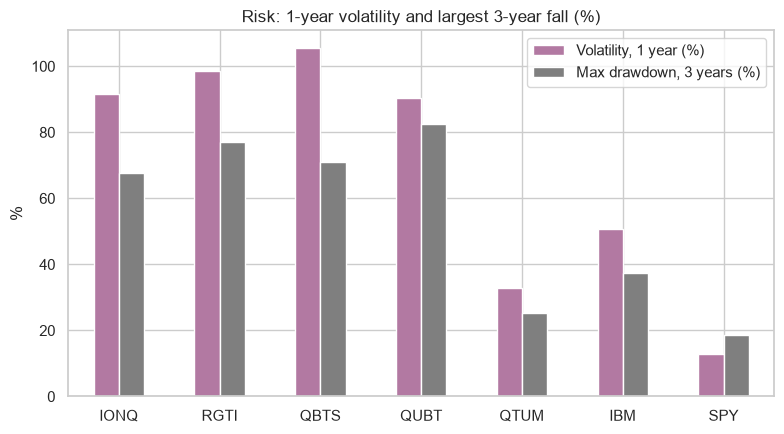

In [27]:
risk = quantum_perf.loc[
    ["IONQ", "RGTI", "QBTS", "QUBT", "QTUM", "IBM", "SPY"],
    ["Volatility, 1 year (%)", "Max drawdown, 3 years (%)"],
]
fig, ax = plt.subplots(figsize=(8, 4.5))
risk.assign(**{"Max drawdown, 3 years (%)": risk["Max drawdown, 3 years (%)"].abs()}).plot.bar(
    ax=ax, color=["#B279A2", "#7F7F7F"], rot=0
)
ax.set_title("Risk: 1-year volatility and largest 3-year fall (%)")
ax.set_ylabel("%")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

Key facts about quantum computing from recent public sources. Each row links to the page where the number appears.

In [28]:
quantum_facts = pd.DataFrame(
    [
        (
            "Investment in quantum technology start-ups reached US$12.6 billion in 2025, 6.3 times the 2024 level; about 90% went to quantum computing.",
            "McKinsey, Quantum Technology Monitor 2026",
            "2026-04-28",
            "https://www.mckinsey.com/capabilities/mckinsey-technology/our-insights/mckinsey-quantum-technology-monitor-2026-a-commercial-tipping-point",
        ),
        (
            "Quantum computing companies generated more than US$1 billion of revenue worldwide in 2025; McKinsey estimates up to US$4.4 billion by 2028.",
            "McKinsey, Quantum Technology Monitor 2026",
            "2026-04-28",
            "https://www.mckinsey.com/capabilities/mckinsey-technology/our-insights/mckinsey-quantum-technology-monitor-2026-a-commercial-tipping-point",
        ),
        (
            "The US Department of Commerce signed letters of intent with 9 companies for US$2.013 billion of CHIPS Act incentives, including US$1 billion for IBM and US$100 million each for D-Wave and Quantinuum (planned amounts, not final awards).",
            "NIST, US Department of Commerce",
            "2026-05-21",
            "https://www.nist.gov/news-events/news/2026/05/department-commerce-announces-letters-intent-9-companies-2-billion",
        ),
        (
            "IonQ's revenue was US$130.0 million in 2025 (+202%).",
            "IonQ, Q4 and full-year 2025 results",
            "2026-02-25",
            "https://ionq.com/news/ionq-announces-fourth-quarter-and-full-year-2025-financial-results",
        ),
        (
            "IonQ's revenue was US$80.1 million in Q2 2026 (+287% year on year); its 2026 guidance is US$280 to 290 million.",
            "IonQ, Q2 2026 results",
            "2026-08-05",
            "https://ionq.com/news/ionq-announces-record-second-quarter-2026-revenues-growing-287-yoy",
        ),
        (
            "Rigetti's revenue was US$5.1 million in Q2 2026.",
            "Rigetti Computing, Q2 2026 results (SEC Form 8-K)",
            "2026-08-06",
            "https://www.sec.gov/Archives/edgar/data/0001838359/000110465926091979/rgti-20260806xex99d1.htm",
        ),
        (
            "D-Wave's revenue was US$3.1 million in Q2 2026, essentially flat year on year.",
            "D-Wave Quantum, Q2 2026 results",
            "2026-08-06",
            "https://www.dwavequantum.com/company/newsroom/press-release/d-wave-reports-second-quarter-2026-results/",
        ),
        (
            "Quantum Computing Inc.'s revenue was US$5.6 million in Q2 2026, against US$61 thousand in Q2 2025.",
            "Quantum Computing Inc., Q2 2026 results (SEC Form 8-K)",
            "2026-08-10",
            "https://www.sec.gov/Archives/edgar/data/0001758009/000121390026087267/ea030143301ex99-1.htm",
        ),
        (
            "Quantinuum's Helios computer has 98 physical qubits with 99.921% two-qubit gate fidelity and 48 error-corrected logical qubits.",
            "Quantinuum",
            "2025-11-05",
            "https://www.quantinuum.com/press-releases/quantinuum-announces-commercial-launch-of-new-helios-quantum-computer-that-offers-unprecedented-accuracy-to-enable-generative-quantum-ai-genqai",
        ),
        (
            "IBM plans its Nighthawk processor to run circuits of 7,500 gates on up to 360 qubits in 2026 (a roadmap goal).",
            "IBM, quantum roadmap (updated March 2026)",
            "2026-03",
            "https://www.ibm.com/roadmaps/quantum/2026",
        ),
        (
            "DARPA selected 11 companies for Stage B of its Quantum Benchmarking Initiative, which tests whether a utility-scale quantum computer is possible by 2033.",
            "DARPA",
            "2025-11-06",
            "https://www.darpa.mil/research/programs/quantum-benchmarking-initiative/stage-b-selection",
        ),
        (
            "The UK National Cyber Security Centre asks organizations to migrate all systems to post-quantum cryptography by 2035 (plans by 2028, priority migrations by 2031).",
            "UK NCSC",
            "2025-03-20",
            "https://www.ncsc.gov.uk/guidance/pqc-migration-timelines",
        ),
        (
            "NIST selected HQC as a backup to ML-KEM (FIPS 203) for post-quantum encryption; the final standard is expected in 2027.",
            "NIST",
            "2025-03-11",
            "https://www.nist.gov/news-events/news/2025/03/nist-selects-hqc-fifth-algorithm-post-quantum-encryption",
        ),
        (
            "The Defiance Quantum ETF (QTUM) had net assets of US$5.70 billion on 8 October 2026; it is a broad fund whose top holdings include AMD, Palantir, and Cloudflare.",
            "Defiance ETFs",
            "2026-10-08",
            "https://www.defianceetfs.com/qtum/",
        ),
    ],
    columns=["Fact", "Source", "Published", "Link"],
)
quantum_facts

,Fact,Source,Published,Link
0,Investment in quantum technology start-ups rea...,"McKinsey, Quantum Technology Monitor 2026",2026-04-28,https://www.mckinsey.com/capabilities/mckinsey...
1,Quantum computing companies generated more tha...,"McKinsey, Quantum Technology Monitor 2026",2026-04-28,https://www.mckinsey.com/capabilities/mckinsey...
2,The US Department of Commerce signed letters o...,"NIST, US Department of Commerce",2026-05-21,https://www.nist.gov/news-events/news/2026/05/...
3,IonQ's revenue was US$130.0 million in 2025 (+...,"IonQ, Q4 and full-year 2025 results",2026-02-25,https://ionq.com/news/ionq-announces-fourth-qu...
4,IonQ's revenue was US$80.1 million in Q2 2026 ...,"IonQ, Q2 2026 results",2026-08-05,https://ionq.com/news/ionq-announces-record-se...
5,Rigetti's revenue was US$5.1 million in Q2 2026.,"Rigetti Computing, Q2 2026 results (SEC Form 8-K)",2026-08-06,https://www.sec.gov/Archives/edgar/data/000183...
6,D-Wave's revenue was US$3.1 million in Q2 2026...,"D-Wave Quantum, Q2 2026 results",2026-08-06,https://www.dwavequantum.com/company/newsroom/...
7,Quantum Computing Inc.'s revenue was US$5.6 mi...,"Quantum Computing Inc., Q2 2026 results (SEC F...",2026-08-10,https://www.sec.gov/Archives/edgar/data/000175...
8,Quantinuum's Helios computer has 98 physical q...,Quantinuum,2025-11-05,https://www.quantinuum.com/press-releases/quan...
9,IBM plans its Nighthawk processor to run circu...,"IBM, quantum roadmap (updated March 2026)",2026-03,https://www.ibm.com/roadmaps/quantum/2026


## Sector Comparison

The four themes behave very differently. Over five years, quantum computing (QTUM, 25.9% per year) and AI (AIQ, 16.8%) beat the S&P 500 (13.6%), while robotics (BOTZ, -0.1%) and water (PHO, 4.8%) lagged it. AI, robotics, and quantum ETFs move closely together (correlations of 0.81 to 0.88), so they add little diversification to each other; water ETFs are much less correlated with them (0.40 to 0.60).

One ETF per theme and two benchmarks over five years. AI (AIQ), water (PHO), robotics (BOTZ), and quantum computing (QTUM), with the S&P 500 (SPY) and the MSCI All Country World Index (ACWI), indexed to 100 on 1 October 2021.

In [29]:
themes = ["AIQ", "PHO", "BOTZ", "QTUM", "SPY", "ACWI"]
fig = line_chart(
    indexed(themes, START),
    "One ETF per theme and two benchmarks, last 5 years",
    "Indexed to 100 (Oct 2021)",
)
fig.show()

Return and risk over the last year for every ETF and company. Each point is one ticker, colored by sector: the higher, the better the return; the further right, the more volatile. Hover over a point for its name.

In [30]:
everything = pd.concat([ai_perf, water_perf, robotics_perf, quantum_perf])
everything = everything[~everything.index.duplicated()].join(pd.Series(SECTOR_OF, name="Sector"))
fig = px.scatter(
    everything.reset_index(),
    x="Volatility, 1 year (%)",
    y="1 year (%)",
    color="Sector",
    hover_name="Name",
    text="Ticker",
    color_discrete_map=SECTOR_COLORS,
    title="Return and risk over the last year: every ETF and company",
)
fig.update_traces(textposition="top center")
fig.show()

Correlation of daily returns over the last two years. A value near 1 means that two ETFs rise and fall together; water ETFs (PHO, CGW) are the least correlated with the others.

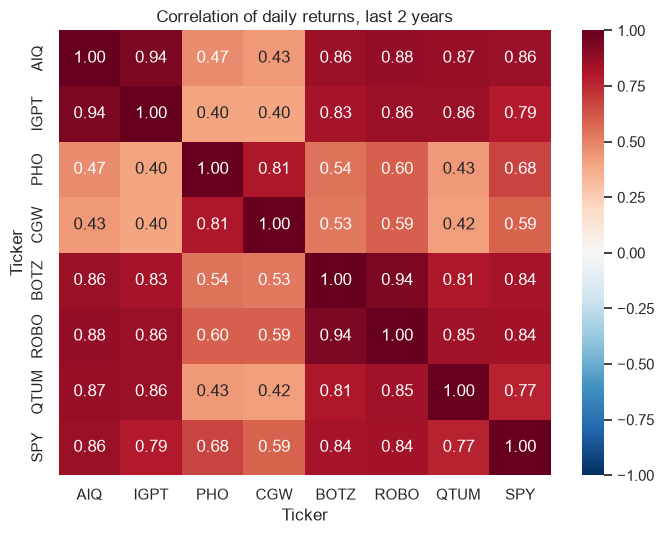

In [31]:
corr = (
    returns[["AIQ", "IGPT", "PHO", "CGW", "BOTZ", "ROBO", "QTUM", "SPY"]].loc["2024-10-08":].corr()
)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of daily returns, last 2 years")
plt.tight_layout()
plt.show()

Calendar-year returns of the thematic ETFs and the benchmarks (%). All themes fell in 2022. QTUM had the highest return in 2024 and 2025, and IGPT leads in 2026 so far.

In [32]:
yearly = (
    prices[["AIQ", "IGPT", "PHO", "CGW", "BOTZ", "ROBO", "QTUM", "SPY", "ACWI"]]
    .resample("YE")
    .last()
)
calendar = (yearly.pct_change() * 100).iloc[1:].round(1)
calendar.index = [str(d.year) if d.year < 2026 else "2026 to Oct 8" for d in calendar.index]
calendar.T

,2022,2023,2024,2025,2026 to Oct 8
Ticker,,,,,
AIQ,-36.4,55.4,24.1,31.9,29.0
IGPT,-27.7,27.3,17.1,31.6,68.2
PHO,-14.9,18.9,8.6,7.6,-2.8
CGW,-22.0,15.5,4.5,18.1,1.0
BOTZ,-42.7,39.0,12.3,14.2,-3.8
ROBO,-33.9,23.7,-1.3,23.7,15.5
QTUM,-28.8,39.8,50.5,36.7,38.5
SPY,-18.2,26.2,24.9,17.7,14.4
ACWI,-18.4,22.3,17.4,22.4,13.7


Data sources and terms of use. Yahoo Finance data is for personal research; check its terms before you publish the data itself. The sector facts in each section link to their sources.

In [33]:
sources = pd.DataFrame(
    [
        (
            "Yahoo Finance (via yfinance)",
            "Daily prices adjusted for dividends and splits; company names, market values, and annual revenue",
            "Yahoo terms of service; personal research use",
            "https://finance.yahoo.com",
        ),
        (
            "Our World in Data",
            "AI private investment (Quid via AI Index 2026), large-scale AI systems (Epoch AI), industrial robot installations (IFR), water stress (FAO AQUASTAT)",
            "CC BY 4.0 (check each dataset's original source)",
            "https://ourworldindata.org",
        ),
        (
            "Epoch AI",
            "Notable AI models: publication date, organization, domain, training compute",
            "CC BY 4.0",
            "https://epoch.ai/data/notable_ai_models.csv",
        ),
        (
            "World Bank",
            "People using safely managed drinking water services (SH.H2O.SMDW.ZS), from WHO/UNICEF JMP",
            "CC BY 4.0",
            "https://data.worldbank.org/indicator/SH.H2O.SMDW.ZS",
        ),
    ],
    columns=["Source", "Data", "Terms", "Link"],
)
sources

,Source,Data,Terms,Link
0,Yahoo Finance (via yfinance),Daily prices adjusted for dividends and splits...,Yahoo terms of service; personal research use,https://finance.yahoo.com
1,Our World in Data,AI private investment (Quid via AI Index 2026)...,CC BY 4.0 (check each dataset's original source),https://ourworldindata.org
2,Epoch AI,"Notable AI models: publication date, organizat...",CC BY 4.0,https://epoch.ai/data/notable_ai_models.csv
3,World Bank,People using safely managed drinking water ser...,CC BY 4.0,https://data.worldbank.org/indicator/SH.H2O.SM...
